## **Actividad - Clase 8**

**Estudiante:** Gabriela Bacchiani

**Materia:** Aprendizaje Automático

**Objetivo:** Identificar segmentos latentes de clientes a partir de sus comportamientos de compra y uso del sitio, sin etiquetas previas.

## **Paso 1**: Carga de Librerías y Dataset.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset_segmentacion_clientes.csv")

df = df.rename(columns={
    "purchase_freq_month": "frecuencia_compra_mes",
    "avg_basket_usd": "ticket_promedio_usd",
    "time_on_site_min": "tiempo_sitio_min",
    "discount_sensitivity": "sensibilidad_descuentos",
    "returns_rate": "tasa_devoluciones",
    "noise_gauss": "ruido_gauss",
    "noise_uniform": "ruido_uniforme",
})

df.head()

,frecuencia_compra_mes,ticket_promedio_usd,tiempo_sitio_min,sensibilidad_descuentos,tasa_devoluciones,ruido_gauss,ruido_uniforme
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


## Conocer el tamaño y tipos de columnas

In [33]:
print(df.shape)
df.info()

(700, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   frecuencia_compra_mes    700 non-null    float64
 1   ticket_promedio_usd      700 non-null    float64
 2   tiempo_sitio_min         700 non-null    float64
 3   sensibilidad_descuentos  700 non-null    float64
 4   tasa_devoluciones        700 non-null    float64
 5   ruido_gauss              700 non-null    float64
 6   ruido_uniforme           700 non-null    float64
dtypes: float64(7)
memory usage: 38.4 KB


Este dataset cuenta con 700 filas y 7 columnas. No tiene valores nulos. Todas las columnas son números con decimales.

## Comprobar si hay valores faltantes

In [34]:
df.isna().sum()

,0
frecuencia_compra_mes,0
ticket_promedio_usd,0
tiempo_sitio_min,0
sensibilidad_descuentos,0
tasa_devoluciones,0
ruido_gauss,0
ruido_uniforme,0


No hay valores faltantes.

## Resumen de estadísticas descriptivas

In [35]:
df.describe().round(2)

,frecuencia_compra_mes,ticket_promedio_usd,tiempo_sitio_min,sensibilidad_descuentos,tasa_devoluciones,ruido_gauss,ruido_uniforme
count,700.00,700.00,700.00,700.00,700.00,700.00,700.00
mean,5.88,248.17,16.78,0.43,0.34,0.02,-0.01
std,4.47,154.90,12.91,0.43,0.36,1.01,1.68
min,0.10,86.99,3.16,0.00,0.00,-3.57,-2.99
25%,2.28,90.77,6.60,0.00,0.00,-0.65,-1.42
50%,4.13,180.22,9.97,0.30,0.17,0.08,0.01
75%,11.21,449.72,34.34,1.00,0.80,0.73,1.41
max,14.60,452.97,38.35,1.00,0.80,2.86,3.00


### Análisis de las estadísticas descriptivas

**Escalas muy distintas entre variables.** Las variables del dataset se miden en unidades y rangos muy diferentes:


| Variable | Rango | Desvío estándar |
|---|---|---|
| `ticket_promedio_usd` | 87 a 453 USD | 154,90 |
| `tiempo_sitio_min` | 3,2 a 38,4 min | 12,91 |
| `frecuencia_compra_mes` | 0,1 a 14,6 compras | 4,47 |
| `sensibilidad_descuentos` | 0 a 1 | 0,43 |
| `tasa_devoluciones` | 0 a 0,8 | 0,36 |

Como K-Means agrupa según la distancia euclidiana entre clientes, una variable con valores grandes como el ticket promedio dominaría el cálculo: una diferencia de 50 USD pesaría mucho más que pasar de una sensibilidad a descuentos de 0,1 a 0,9. Por eso será necesario **escalar las variables** antes de aplicar el modelo, para que todas aporten de forma comparable a la distancia.

**Indicios de grupos.** En varias variables los cuartiles están muy separados entre sí. Por ejemplo, en `ticket_promedio_usd` el 25 % de los clientes gasta menos de 91 USD, la mediana es 180 USD y el 75 % está por debajo de 450 USD, con un máximo de 453 USD. Esto sugiere que los valores no siguen una única distribución centrada, sino que podrían concentrarse en varios niveles, lo cual se verificará con los histogramas.

**Variables de ruido.** `ruido_gauss` y `ruido_uniform` tienen media cercana a 0 y valores simétricos alrededor de ella, sin relación aparente con el comportamiento de compra. Su inclusión se evaluará en el paso de selección de variables.

**Calidad de datos.** Las 700 filas tienen valores en todas las columnas, por lo que no es necesario imputar faltantes.

## Gráficos: Histograma

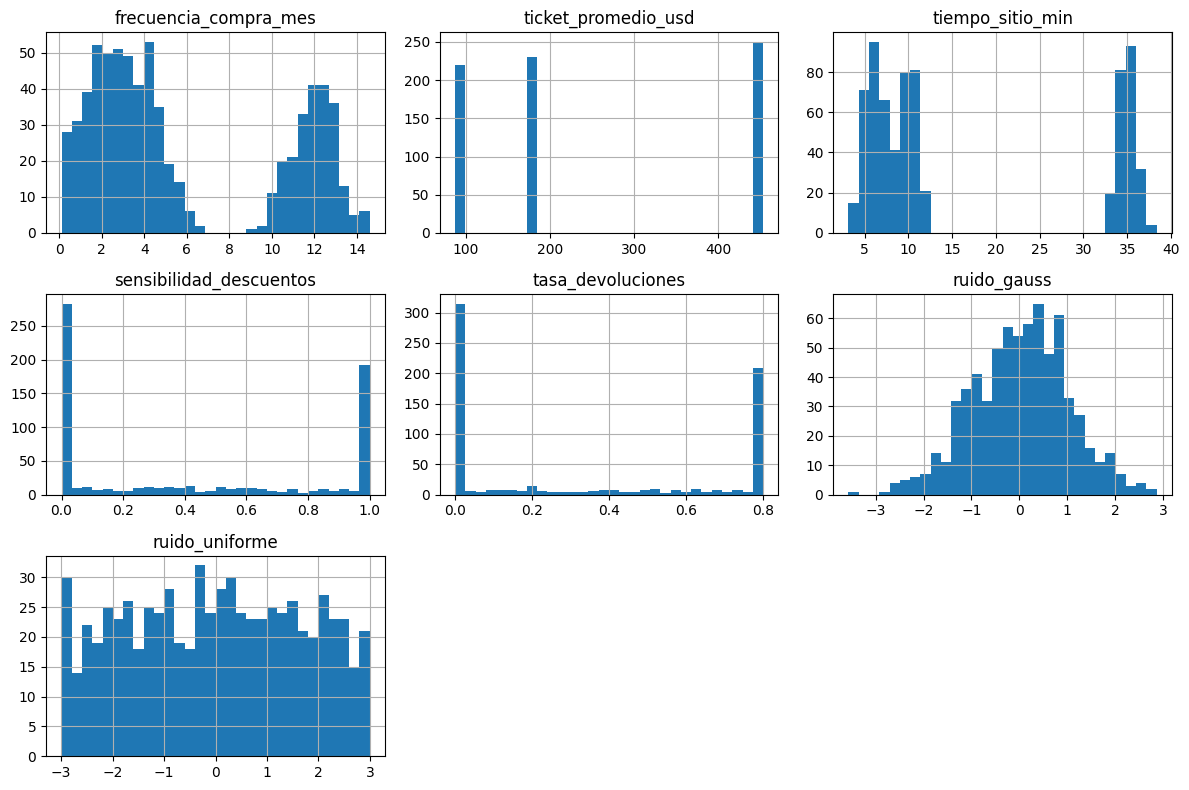

In [36]:
df.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

### Análisis de los histogramas

Las distribuciones de las variables de comportamiento no tienen una única forma de campana, sino que muestran concentraciones separadas, lo que indica la posible existencia de segmentos de clientes:

- **`frecuencia_compra_mes`**: dos grupos claramente separados, uno entre 0 y 6 compras mensuales (con valores más frecuentes entre 2 y 4) y otro entre 10 y 14, con pico cerca de 12. Prácticamente no hay clientes entre 6,5 y 9,5.
- **`ticket_promedio_usd`**: tres niveles muy marcados, alrededor de 90, 180 y 450 USD, sin valores intermedios. Es la variable con la separación más clara.
- **`tiempo_sitio_min`**: dos grupos bien diferenciados, uno entre 4 y 12 minutos y otro entre 33 y 38 minutos.
- **`sensibilidad_descuentos`** y **`tasa_devoluciones`**: forma de "U", con muchos clientes concentrados en el valor mínimo (0) y en el máximo (1 y 0,8 respectivamente), y el resto repartido de forma pareja entre ambos extremos. Esto sugiere que los valores están acotados a esos límites.

Las variables no muestran todas la misma cantidad de grupos (dos en frecuencia y tiempo, tres en ticket), por lo que el número de segmentos no puede deducirse de una sola variable: surgirá de la combinación entre ellas. Esto se analizará con el método del codo.

## Correlación de las variables ruido_gauss y ruido_uniforme

In [37]:
df.corr().round(2)[["ruido_gauss", "ruido_uniforme"]]

,ruido_gauss,ruido_uniforme
frecuencia_compra_mes,0.01,-0.02
ticket_promedio_usd,0.03,0.06
tiempo_sitio_min,0.01,-0.02
sensibilidad_descuentos,-0.01,-0.04
tasa_devoluciones,-0.05,0.01
ruido_gauss,1.00,-0.05
ruido_uniforme,-0.05,1.00


### Exclusión de las variables de ruido

Las variables `ruido_gauss` y `ruido_uniforme` no se incluirán en el modelo, por los siguientes motivos:

- **Distribución sin estructura:** el histograma de `ruido_gauss` muestra una única campana centrada en 0, y el de `ruido_uniforme` una distribución plana entre -3 y 3. A diferencia de las variables de comportamiento, ninguna presenta concentraciones separadas que sugieran grupos.
- **Sin relación con el comportamiento de compra:** sus correlaciones con las demás variables están entre -0,05 y 0,06, es decir, prácticamente nulas.
- **Efecto negativo sobre K-Means:** como el algoritmo agrupa por distancia euclidiana y, una vez escaladas, todas las variables pesan lo mismo, incluir ruido agregaría diferencias aleatorias entre clientes que tienen un comportamiento similar. Esto dificultaría que el modelo encuentre los grupos reales.
- **Sin significado de negocio:** no forman parte de las variables descriptas en la consigna y no aportarían a la interpretación de los perfiles de clientes.

Por lo tanto, el análisis se realizará con las cinco variables de comportamiento: `frecuencia_compra_mes`, `ticket_promedio_usd`, `tiempo_sitio_min`, `sensibilidad_descuentos` y `tasa_devoluciones`.

## **Paso 2:** Selección de variables

In [38]:
variables = [
    "frecuencia_compra_mes",
    "ticket_promedio_usd",
    "tiempo_sitio_min",
    "sensibilidad_descuentos",
    "tasa_devoluciones",
]

X = df[variables]
X.head()

,frecuencia_compra_mes,ticket_promedio_usd,tiempo_sitio_min,sensibilidad_descuentos,tasa_devoluciones
0,11.152508,181.300834,33.564036,1.000000,0.800000
1,12.053451,178.637272,35.432081,0.784974,0.000000
2,2.203006,450.185298,7.030757,0.898297,0.000000
3,4.233314,89.006342,10.834453,0.000000,0.800000
4,1.716799,449.773982,7.254548,0.000000,0.003279


## **Paso 3:** Escalar las variables

In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

X_escalado_df = pd.DataFrame(X_escalado, columns=variables)
X_escalado_df.describe().round(2)

,frecuencia_compra_mes,ticket_promedio_usd,tiempo_sitio_min,sensibilidad_descuentos,tasa_devoluciones
count,700.00,700.00,700.00,700.00,700.00
mean,-0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.29,-1.04,-1.06,-0.99,-0.95
25%,-0.81,-1.02,-0.79,-0.99,-0.95
50%,-0.39,-0.44,-0.53,-0.30,-0.48
75%,1.20,1.30,1.36,1.33,1.30
max,1.95,1.32,1.67,1.33,1.30


### Escalado de las variables

Se aplicó **estandarización** con `StandardScaler`, que transforma cada variable restándole su media y dividiéndola por su desvío estándar:

$$z = \frac{\text{valor} - \text{media}}{\text{desvío}}$$

**Por qué era necesario:** como se observó en las estadísticas descriptivas, las variables tenían escalas muy distintas (por ejemplo, el ticket promedio tenía un desvío de 154,90 y la sensibilidad a descuentos de 0,43). Dado que K-Means agrupa según la distancia euclidiana, sin escalar las variables con valores más grandes habrían dominado la formación de los grupos.

**Verificación:** después del escalado, todas las variables quedaron con media 0 y desvío estándar 1, por lo que ahora aportan de forma comparable al cálculo de distancias.

**Interpretación de los valores escalados:** cada valor indica a cuántos desvíos estándar del promedio se encuentra un cliente en esa variable. Los valores negativos corresponden a clientes por debajo del promedio y los positivos a clientes por encima. Por ejemplo, el ticket mínimo de 86,99 USD quedó transformado en −1,04, lo que indica que ese cliente gasta aproximadamente un desvío por debajo del ticket promedio (248,17 USD).

Para la interpretación final de los perfiles, los centroides se volverán a expresar en sus unidades originales mediante `scaler.inverse_transform`.

## **Paso 4:** Aplicar el método del codo

Para entrenar k-means varias veces, una por cada valor de K, es necesario guardar la inercia de cada una y graficarla

## Calcular la inercia para k

In [40]:
from sklearn.cluster import KMeans

valores_k = range(2, 7)   # k = 2, 3, 4, 5, 6
inercias = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    modelo.fit(X_escalado)
    inercias.append(modelo.inertia_)

for k, inercia in zip(valores_k, inercias):
    print(f"k = {k}: inercia = {inercia:.1f}")

k = 2: inercia = 2088.9
k = 3: inercia = 1408.7
k = 4: inercia = 1173.4
k = 5: inercia = 997.7
k = 6: inercia = 762.5


## Graficar

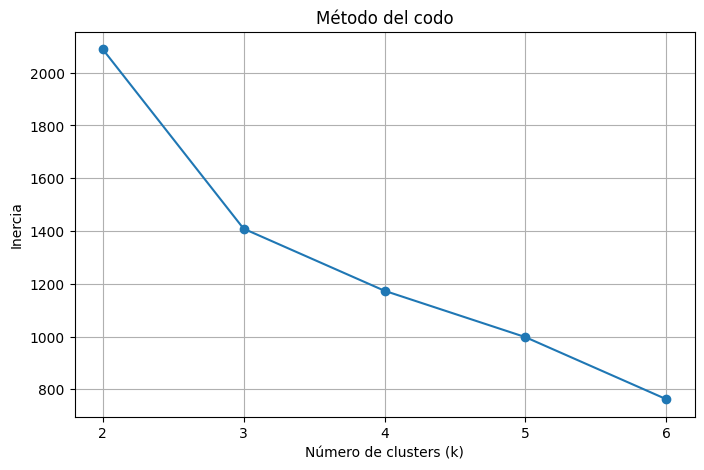

In [41]:
plt.figure(figsize=(8, 5))
plt.plot(list(valores_k), inercias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

## Calcular cuánto baja la inercia en cada paso

In [42]:
tabla_codo = pd.DataFrame({"k": list(valores_k), "inercia": inercias})
tabla_codo["disminución"] = tabla_codo["inercia"].diff() * -1
tabla_codo["disminución_%"] = (tabla_codo["inercia"].pct_change() * -100).round(1)
tabla_codo.round(1)

,k,inercia,disminución,disminución_%
0,2,2088.9,NaN,NaN
1,3,1408.7,680.2,32.6
2,4,1173.4,235.3,16.7
3,5,997.7,175.7,15.0
4,6,762.5,235.3,23.6


### Elección de k

Se calculó la inercia de K-Means para k entre 2 y 6. La mayor disminución se produce al pasar de 2 a 3 clusters (32,6 %). A partir de k = 3, las mejoras se reducen notablemente: 16,7 % al pasar a 4 clusters y 15,0 % al pasar a 5. Esto indica que **k = 3 es el codo de la curva**: agregar más grupos ya no reduce la inercia de manera significativa.

Se observa un nuevo aumento en la disminución al pasar de 5 a 6 clusters (23,6 %), lo que muestra que el codo no es completamente nítido, una limitación conocida del método dado que la inercia no es una métrica normalizada. Sin embargo, esa mejora es menor a la obtenida con k = 3, y un modelo con más segmentos resultaría más difícil de interpretar y de aplicar en decisiones de negocio.

La elección de k = 3 es además coherente con el análisis exploratorio: la variable `ticket_promedio_usd`, la de separación más marcada, mostraba tres niveles bien diferenciados (alrededor de 90, 180 y 450 USD).

Por lo tanto, se utilizará **k = 3** para el modelo final.

## **Paso 5:** Entrenar el modelo

## Entrenar con k = 3



In [43]:
k_final = 3

modelo_final = KMeans(n_clusters=k_final, init="k-means++", n_init=10, random_state=42)
modelo_final.fit(X_escalado)

print(f"Inercia del modelo final: {modelo_final.inertia_:.1f}")

Inercia del modelo final: 1408.7


## Asignar cada cliente a su cluster

In [44]:
df["cluster"] = modelo_final.labels_
df.head()

,frecuencia_compra_mes,ticket_promedio_usd,tiempo_sitio_min,sensibilidad_descuentos,tasa_devoluciones,ruido_gauss,ruido_uniforme,cluster
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905,0
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460,0
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173,1
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026,2
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522,1


Al dataframe original le agreamos una columna nueva, sin escalar, así cada cliente tiene sus valores realies y su grupo en la misma fila. El número de cluster no tiene un orden de jerarquía.

## Comprobar cuántos clientes hay en cada cluster

In [45]:
df["cluster"].value_counts().sort_index()

,count
cluster,
0,230
1,250
2,220


En el cluster 0 quedaron 230 clientes, en el cluster 1 quedaron 250 clientes, y en el cluster 2 quedaron 220 clientes, lo que sumado dan 700 clientes en total como habíamos constatado en el paso 1.


## Visualizar los grupos

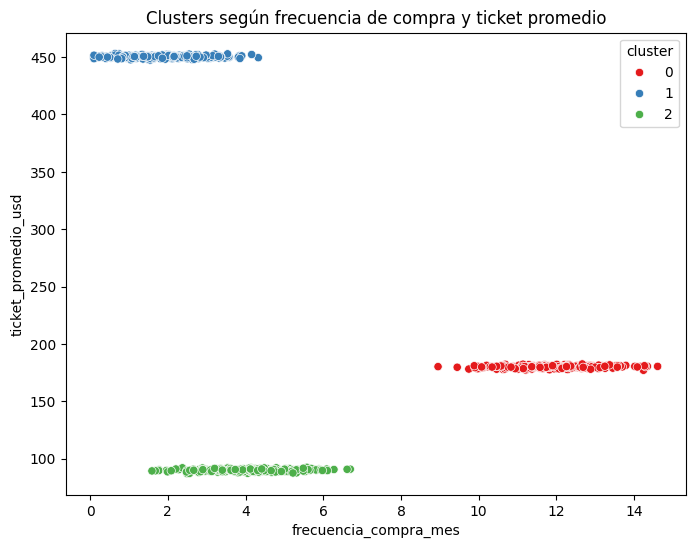

In [46]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="frecuencia_compra_mes",
    y="ticket_promedio_usd",
    hue="cluster",
    palette="Set1",
)
plt.title("Clusters según frecuencia de compra y ticket promedio")
plt.show()

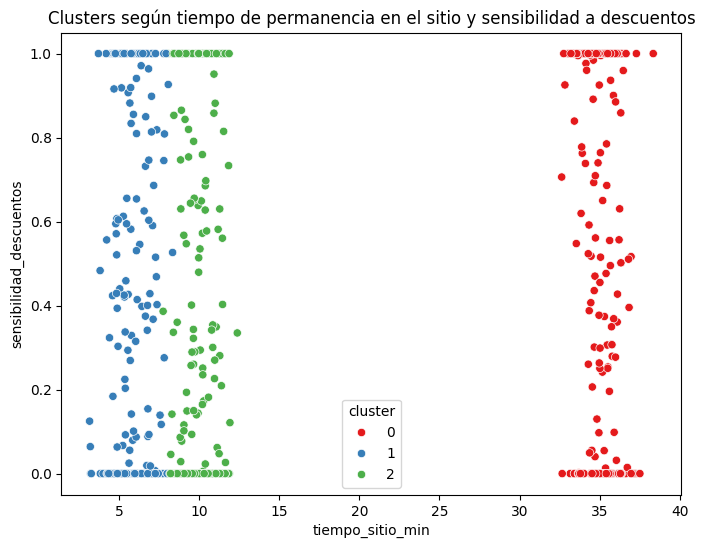

In [47]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="tiempo_sitio_min",
    y="sensibilidad_descuentos",
    hue="cluster",
    palette="Set1",
)
plt.title("Clusters según tiempo de permanencia en el sitio y sensibilidad a descuentos")
plt.show()

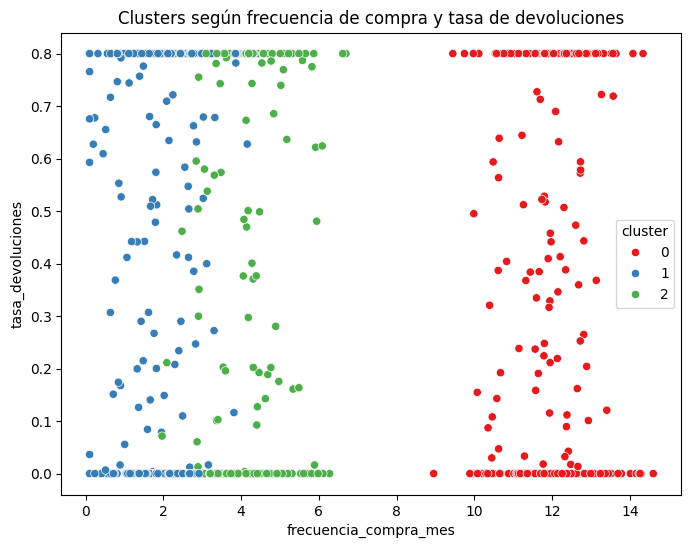

In [48]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="frecuencia_compra_mes",
    y="tasa_devoluciones",
    hue="cluster",
    palette="Set1",
)
plt.title("Clusters según frecuencia de compra y tasa de devoluciones")
plt.show()

## **Paso 6:** Interpretar los centroides

## Centroides en unidades reales

In [49]:
centroides_escalados = modelo_final.cluster_centers_
centroides_reales = scaler.inverse_transform(centroides_escalados)

tabla_centroides = pd.DataFrame(centroides_reales, columns=variables)
tabla_centroides.index.name = "cluster"
tabla_centroides["cantidad_clientes"] = df["cluster"].value_counts().sort_index()
tabla_centroides.round(2)

,frecuencia_compra_mes,ticket_promedio_usd,tiempo_sitio_min,sensibilidad_descuentos,tasa_devoluciones,cantidad_clientes
cluster,,,,,,
0,11.96,180.00,35.02,0.54,0.33,230
1,1.85,450.12,5.97,0.36,0.38,250
2,4.09,89.96,10.00,0.38,0.30,220


## Verificación cruzada

In [50]:
df.groupby("cluster")[variables].mean().round(2)

,frecuencia_compra_mes,ticket_promedio_usd,tiempo_sitio_min,sensibilidad_descuentos,tasa_devoluciones
cluster,,,,,
0,11.96,180.00,35.02,0.54,0.33
1,1.85,450.12,5.97,0.36,0.38
2,4.09,89.96,10.00,0.38,0.30


Calculamos el promedio de cada variable dentro de cada cluster, usando los datos originales. Verificamos que los valores son los mismos de la tabla anterior, porque un centroide es justamente el promedio de los clientes de su grupo.

## Graficamos un mapa de calor

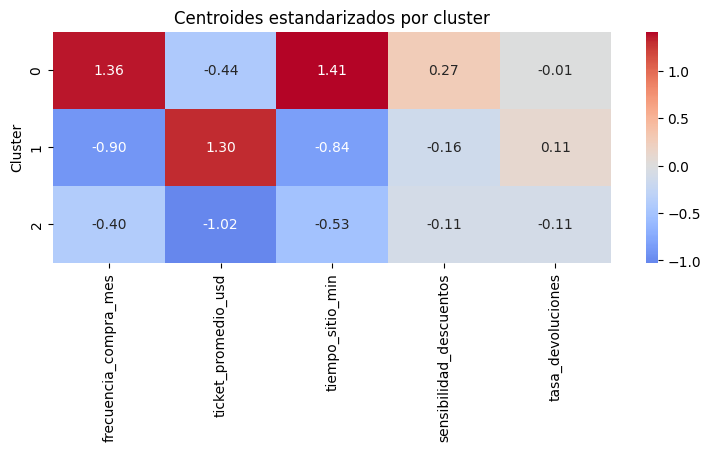

In [51]:
tabla_z = pd.DataFrame(centroides_escalados, columns=variables)

plt.figure(figsize=(9, 3))
sns.heatmap(tabla_z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Centroides estandarizados por cluster")
plt.ylabel("Cluster")
plt.show()

### Análisis con los patrones planteados en la consigna a partir de los centroides y gráfico de color

**1. Frecuencia alta, ticket bajo y alta sensibilidad a descuentos: se cumple parcialmente.**
El cluster 0 tiene la mayor frecuencia de compra (11,96 compras/mes) y la mayor sensibilidad a descuentos (0,54), aunque esta última por una diferencia leve. Sin embargo, su ticket promedio no es bajo sino medio (180 USD). El ticket más bajo (90 USD) corresponde al cluster 2, de frecuencia media.

**2. Frecuencia baja, ticket alto y baja sensibilidad: se cumple.**
El cluster 1 tiene la menor frecuencia (1,85 compras/mes) y el ticket más alto (450 USD), es decir, compras esporádicas pero grandes. Su sensibilidad a descuentos es la más baja (0,36), aunque muy cercana a la del cluster 2 (0,38).

**3. Tiempo en sitio y tasa de devoluciones diferenciados: no se cumple.**
El tiempo en sitio sí distingue claramente a los grupos (35 minutos en el cluster 0 frente a 6 y 10 minutos en los otros). En cambio, la tasa de devoluciones es similar en los tres clusters (entre 0,30 y 0,38). Además, el grupo que menos tiempo pasa en el sitio (cluster 1) es el que devuelve levemente más, lo opuesto a la relación planteada.

**Conclusión:** la segmentación está determinada principalmente por la frecuencia de compra, el ticket promedio y el tiempo en sitio, que presentan diferencias marcadas entre clusters (valores estandarizados de hasta ±1,4). La sensibilidad a descuentos y la tasa de devoluciones aportan poca diferenciación (valores estandarizados entre −0,16 y 0,27): dentro de cada grupo conviven clientes con valores mínimos y máximos en ambas variables.

## Perfiles de clientes y estrategias sugeridas

**Cluster 0 – Clientes frecuentes y comprometidos** (230 clientes)
Este grupo se caracteriza por tener una alta frecuencia de compra (≈12 por mes), ticket medio (≈180 USD) y la mayor permanencia en el sitio (≈35 minutos). Son clientes muy vinculados con la tienda.
*Estrategia:* fidelización mediante programas de puntos o beneficios por recurrencia, y recomendaciones personalizadas durante la navegación para aumentar el valor de cada compra.

**Cluster 1 – Compradores premium ocasionales** (250 clientes)
Este grupo, en cambio, tiene una baja frecuencia de compra (≈2 por mes) pero el ticket más alto (≈450 USD), con visitas breves al sitio (≈6 minutos). Realizan compras esporádicas pero de alto valor.
*Estrategia:* foco en upselling premium y experiencia exclusiva (atención personalizada, productos de gama alta, navegación ágil), junto con recordatorios para aumentar la frecuencia de compra. No se recomiendan estrategias basadas en descuentos, ya que su ticket alto no está asociado a una mayor sensibilidad a descuentos.

**Cluster 2 – Compradores de bajo ticket** (220 clientes)
Frecuencia media (≈4 por mes), el ticket más bajo (≈90 USD) y visitas cortas (≈10 minutos).
*Estrategia:* aumentar el valor de cada compra mediante combos, promociones por cantidad o envío gratis a partir de un monto mínimo.

**Nota:** las estrategias se basan en las variables que mostraron diferencias claras entre grupos (frecuencia, ticket y tiempo en sitio). La sensibilidad a descuentos y la tasa de devoluciones no se utilizaron para definir estrategias, dado que presentan valores similares en los tres clusters.

## **Conclusión**

El objetivo de esta actividad fue identificar segmentos latentes de clientes a partir de su comportamiento de compra y uso del sitio, sin contar con etiquetas previas. Para ello se aplicó el algoritmo K-Means sobre cinco variables de comportamiento, previamente estandarizadas, y se excluyeron las dos variables de ruido por no presentar estructura ni relación con las demás.

Mediante el método del codo se eligió **k = 3**, valor que coincide con los tres niveles de ticket observados en el análisis exploratorio. El modelo identificó tres segmentos de tamaño similar (230, 250 y 220 clientes): clientes frecuentes y comprometidos, compradores premium ocasionales y compradores de bajo ticket. Estos grupos se diferencian principalmente por la frecuencia de compra, el ticket promedio y el tiempo de permanencia en el sitio.

Al contrastar los resultados con los patrones planteados en la consigna, uno se cumplió, otro se cumplió parcialmente y el tercero no se verificó, ya que la sensibilidad a descuentos y la tasa de devoluciones presentan valores similares en los tres grupos.

**Limitaciones:** el codo de la curva no fue completamente nítido, ya que la disminución de la inercia volvió a aumentar al pasar de 5 a 6 clusters. Además, como el algoritmo no utiliza etiquetas, no es posible medir un porcentaje de acierto como en el ejemplo de iris visto en clase: la validez de los segmentos se apoya en su coherencia con el análisis exploratorio y en su interpretabilidad.

Como posible mejora, podría complementarse la elección de k con otras métricas de evaluación de clustering, o analizar si la sensibilidad a descuentos y la tasa de devoluciones permiten distinguir subgrupos dentro de cada segmento.